# Reading and Understanding the Data

## Importing Libraries, Warnings, and Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Importing Libraries
import pandas as pd
import numpy as np
pd.set_option('display.max_columns', 500)

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
import statsmodels.api as sm
import sklearn

In [4]:
# Ignoring Warnings
import warnings
warnings.filterwarnings('ignore')

In [5]:
# Importing Data
Bike = pd.read_csv("/content/drive/MyDrive/Linear Regression Assignment/day.csv")



---
## Understanding and Manipulating Data


In [6]:
# Reading Data
Bike.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,1,1,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,2,1,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,3,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,4,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,5,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [7]:
# Determining the number of rows and columns
Bike.shape

(730, 16)

There are 730 rows and 16 columns in the data.

In [8]:
# Checking the columns in the dataset
Bike.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000
mean,365.500000,2.498630,0.500000,6.526027,0.028767,2.995890,0.690411,1.394521,20.319259,23.726322,62.765175,12.763620,849.249315,3658.757534,4508.006849
std,210.877136,1.110184,0.500343,3.450215,0.167266,2.000339,0.462641,0.544807,7.506729,8.150308,14.237589,5.195841,686.479875,1559.758728,1936.011647
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2.424346,3.953480,0.000000,1.500244,2.000000,20.000000,22.000000
25%,183.250000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,13.811885,16.889713,52.000000,9.041650,316.250000,2502.250000,3169.750000
50%,365.500000,3.000000,0.500000,7.000000,0.000000,3.000000,1.000000,1.000000,20.465826,24.368225,62.625000,12.125325,717.000000,3664.500000,4548.500000
75%,547.750000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,26.880615,30.445775,72.989575,15.625589,1096.500000,4783.250000,5966.000000
max,730.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,35.328347,42.044800,97.250000,34.000021,3410.000000,6946.000000,8714.000000


In [9]:
# Checking the datatypes of columns
Bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


In [10]:
# Checking the null values in the dataset
print(Bike.isnull().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


There are no null values in the dataset.

In [11]:
# Checking the duplicated in dataset
Bike_dup_check = Bike.drop_duplicates()
Bike_dup_check.shape

(730, 16)

Data shape of Bike_dup_check and Bike is same. That means that there are no duplicates in the data.

In [12]:
# Checking column names of dataset
Bike.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [13]:
# Renaming columns for better understanding
Bike.rename(columns = {'dteday': 'date', 'yr':'year', 'mnth':'months', 'hum':'humidity', 'cnt':'count'}, inplace= 'True')
Bike.head()

,instant,date,season,year,months,holiday,weekday,workingday,weathersit,temp,atemp,humidity,windspeed,casual,registered,count
0,1,01-01-2018,1,0,1,0,1,1,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,2,1,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,3,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,4,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,5,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600




---
### Converting Datatypes


In [14]:
# Converting columns to 'category' data type

Bike['season']=Bike['season'].astype('category')
Bike['weathersit']=Bike['weathersit'].astype('category')
Bike['months']=Bike['months'].astype('category')
Bike['weekday']=Bike['weekday'].astype('category')

In [15]:
# Converting 'Date' column to 'datetime' dattype
Bike['date'] =  pd.to_datetime(Bike['date'])
Bike['date'].dtype

Bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     730 non-null    int64         
 1   date        730 non-null    datetime64[ns]
 2   season      730 non-null    category      
 3   year        730 non-null    int64         
 4   months      730 non-null    category      
 5   holiday     730 non-null    int64         
 6   weekday     730 non-null    category      
 7   workingday  730 non-null    int64         
 8   weathersit  730 non-null    category      
 9   temp        730 non-null    float64       
 10  atemp       730 non-null    float64       
 11  humidity    730 non-null    float64       
 12  windspeed   730 non-null    float64       
 13  casual      730 non-null    int64         
 14  registered  730 non-null    int64         
 15  count       730 non-null    int64         
dtypes: category(4), datetime64

In [16]:
#Mapping variables season, month, weathersit, weekday

Bike['season']=Bike.season.map({1:'Spring', 2:'Summer',3:'Fall', 4:'Winter' })
Bike['months']=Bike.months.map({1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'June',7:'July',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'})
Bike['weathersit']=Bike.weathersit.map({1: 'Clear',2:'Mist + Cloudy',3:'Light Snow',4:'Snow + Fog'})
Bike['weekday']=Bike.weekday.map({0:'Sun',1:'Mon',2:'Tue',3:'Wed',4:'Thu',5:'Fri',6:'Sat'})

In [17]:
Bike.head()

,instant,date,season,year,months,holiday,weekday,workingday,weathersit,temp,atemp,humidity,windspeed,casual,registered,count
0,1,2018-01-01,Spring,0,Jan,0,Mon,1,Mist + Cloudy,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,2018-02-01,Spring,0,Jan,0,Tue,1,Mist + Cloudy,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,2018-03-01,Spring,0,Jan,0,Wed,1,Clear,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,2018-04-01,Spring,0,Jan,0,Thu,1,Clear,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,2018-05-01,Spring,0,Jan,0,Fri,1,Clear,9.305237,11.46350,43.6957,12.522300,82,1518,1600




---
# Data Visualization

Identify Continuous and Categorical Features


In [18]:
# checking the number of unique values is the columns
Bike.nunique().sort_values()

year            2
holiday         2
workingday      2
weathersit      3
season          4
weekday         7
months         12
temp          498
humidity      594
casual        605
windspeed     649
registered    678
atemp         689
count         695
instant       730
date          730
dtype: int64

For Categorical column the number of unique values <=20.

For Continuous column the number of unique values in a columns >50.


### Numerical Analysis

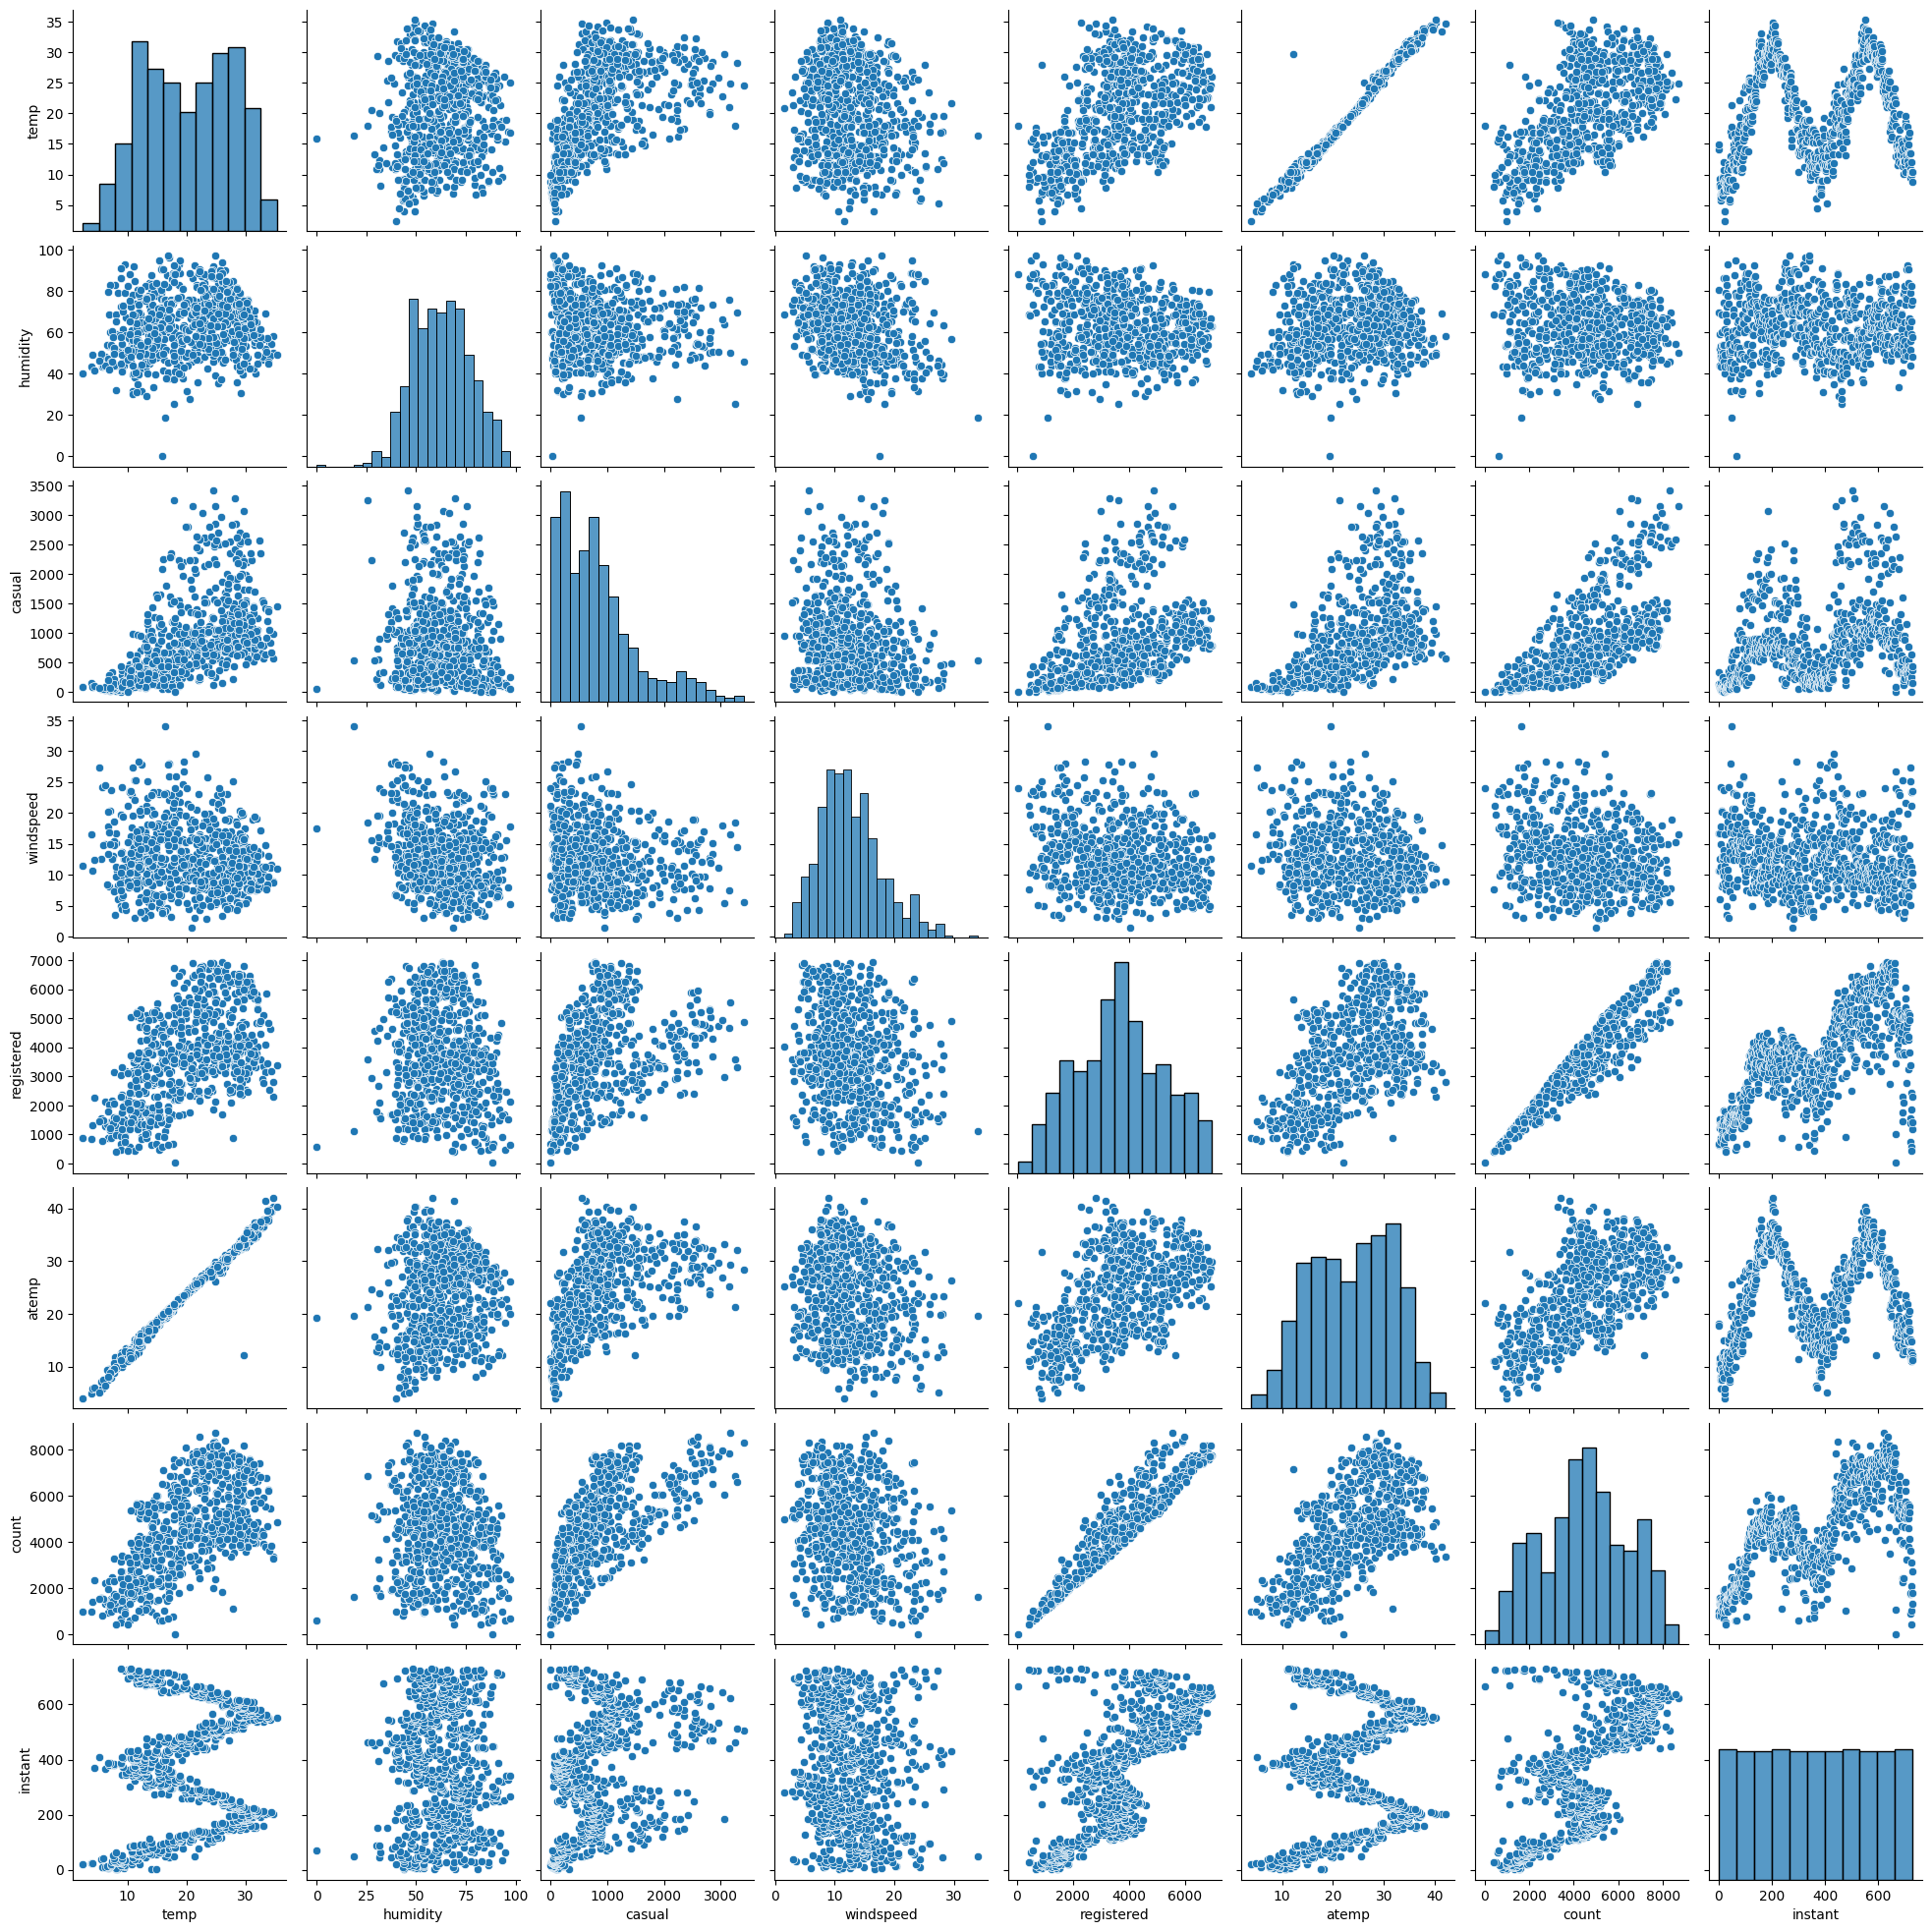

In [19]:
# Pairplotting the numeric variables
Bike_num = Bike[["temp", "humidity",'casual','windspeed','registered','atemp','count','instant']]
sns.pairplot(Bike_num)
plt.show()

<Axes: >

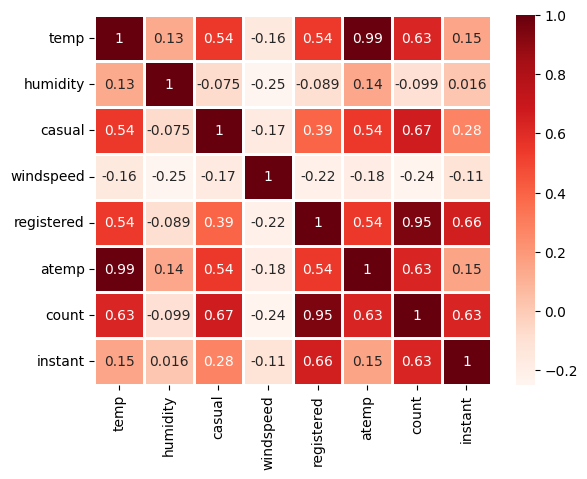

In [20]:
# Plotting heatmap for Numetrtical columns.
plt.figure()
sns.heatmap(Bike_num.corr(), cmap='Reds', annot=True, linewidth=1)

The pairplot and heatmap shows a linear relation between 'temp', 'atemp', and 'count'.

<Figure size 640x480 with 0 Axes>

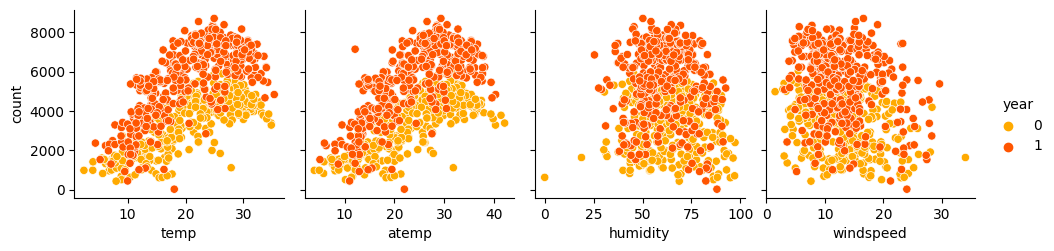

In [21]:
# Checking the relation between the year and the numerical variable :
plt.figure()
ax = sns.pairplot(x_vars=['temp', 'atemp', 'humidity', 'windspeed'], y_vars=['count'] , data=Bike, hue='year', palette='autumn_r')
plt.show()

Here, 0 is year 2018 and 1 is year 2019. The pairplot shows that the bikes are rented more in 2019 compared to 2018.

### Categorical Analysis

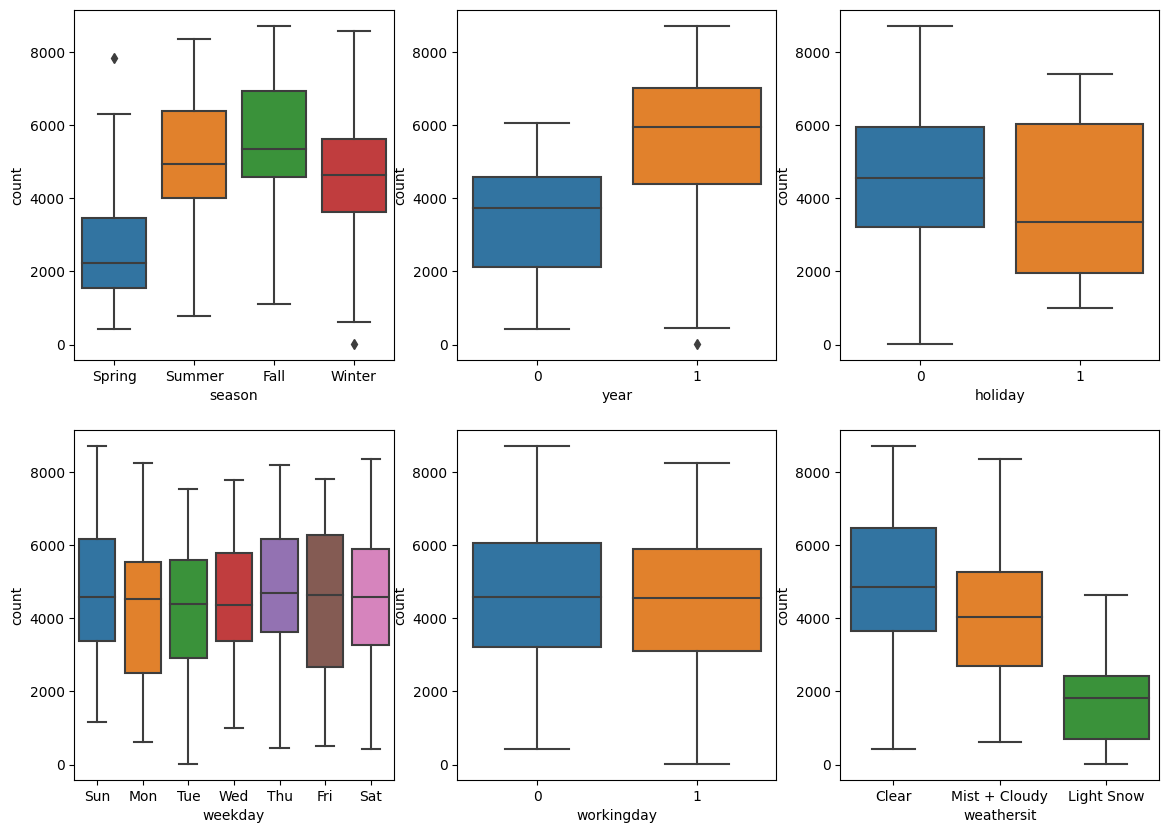

In [22]:
def boxplot_Bike_cat(Bike_cat,target):
    plt.figure(figsize=(14, 10))
    for i in range(0,len(Bike_cat)):
        plt.subplot(2,3,i+1)
        sns.boxplot(x = Bike_cat[i], y = target, data = Bike)
    plt.show()

Bike_cat =['season','year','holiday','weekday','workingday','weathersit']
boxplot_Bike_cat(Bike_cat,'count')

The charts presented above illustrate the associations between categorical variables and a Target variable.

* The fall season exhibits higher bike rental numbers, followed by the summer season.
* Bike rentals were more prevalent in the year 2019 in contrast to 2018.
* Clear and Mist + cloudy weather conditions are associated with increased bike rentals.
* Sunday, Thursday, and Friday are the days when bike rentals are more frequent.



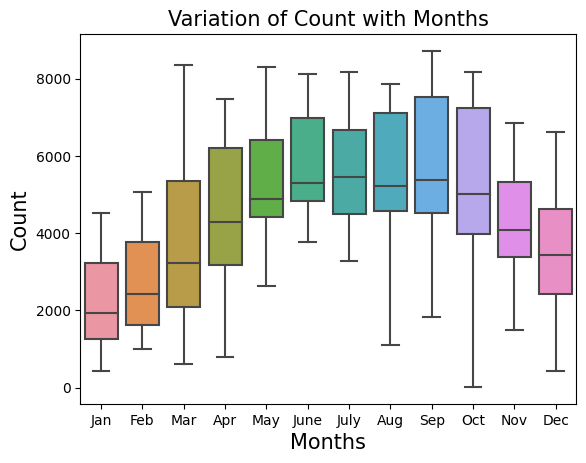

In [23]:
plt.figure()
sns.boxplot(x = 'months', y = 'count', data = Bike).set_title('Variation of Count with Months', fontsize = 15)
plt.xlabel("Months", fontsize = 15)
plt.ylabel("Count", fontsize = 15)
plt.show()

Understaning categorical variables:

In [24]:
# Function to generate statistics data:
def Bike_cat_stats(col):
    cat_df = Bike.groupby(col)['count'].agg(['sum', 'mean','count']).sort_values('sum',ascending = False)
    cat_df['sum_perc']=cat_df['sum']/Bike['count'].sum()*100
    cat_df['count_perc']=cat_df['count']/Bike['count'].count()*100
    return round(cat_df,2)

In [25]:
# Functions to generate plots:
def Bike_cat_plots(col, p, q):
    plt.figure(figsize = (p,q))
    plt.subplot(1,2,1)
    sns.barplot(x = col, y ='count', data=Bike)
    plt.subplot(1,2,2)
    sns.barplot(x= col, y ='count', data=Bike, hue = 'year', palette = 'Paired')
    #plt.legend(labels=['2018', '2019'])
    return

#### Analyzing Seasons

In [26]:
Bike_cat_stats('season')

,sum,mean,count,sum_perc,count_perc
season,,,,,
Fall,1061129,5644.30,188,32.24,25.75
Summer,918589,4992.33,184,27.91,25.21
Winter,841613,4728.16,178,25.57,24.38
Spring,469514,2608.41,180,14.27,24.66


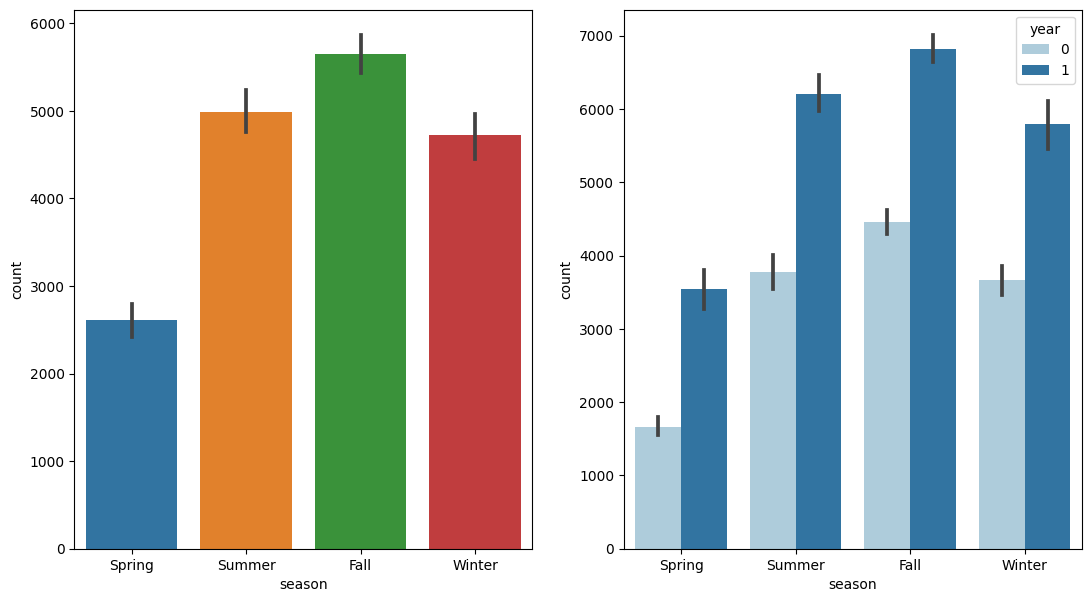

In [27]:
Bike_cat_plots('season', 13, 7)

maximum bike booking happened in Fall, 32%; followed by Summer, Winter, and spring with 27%, 25%, and 14% respectively. More booking happened in 2019 than 2018 during all seasons.

#### Analyzing Months

In [28]:
Bike_cat_stats('months')

,sum,mean,count,sum_perc,count_perc
months,,,,,
Aug,351194,5664.42,62,10.67,8.49
June,346342,5772.37,60,10.52,8.22
Sep,345991,5766.52,60,10.51,8.22
July,344948,5563.68,62,10.48,8.49
May,331686,5349.77,62,10.08,8.49
Oct,322352,5199.23,62,9.80,8.49
Apr,269094,4484.90,60,8.18,8.22
Nov,254831,4247.18,60,7.74,8.22
Mar,228920,3692.26,62,6.96,8.49


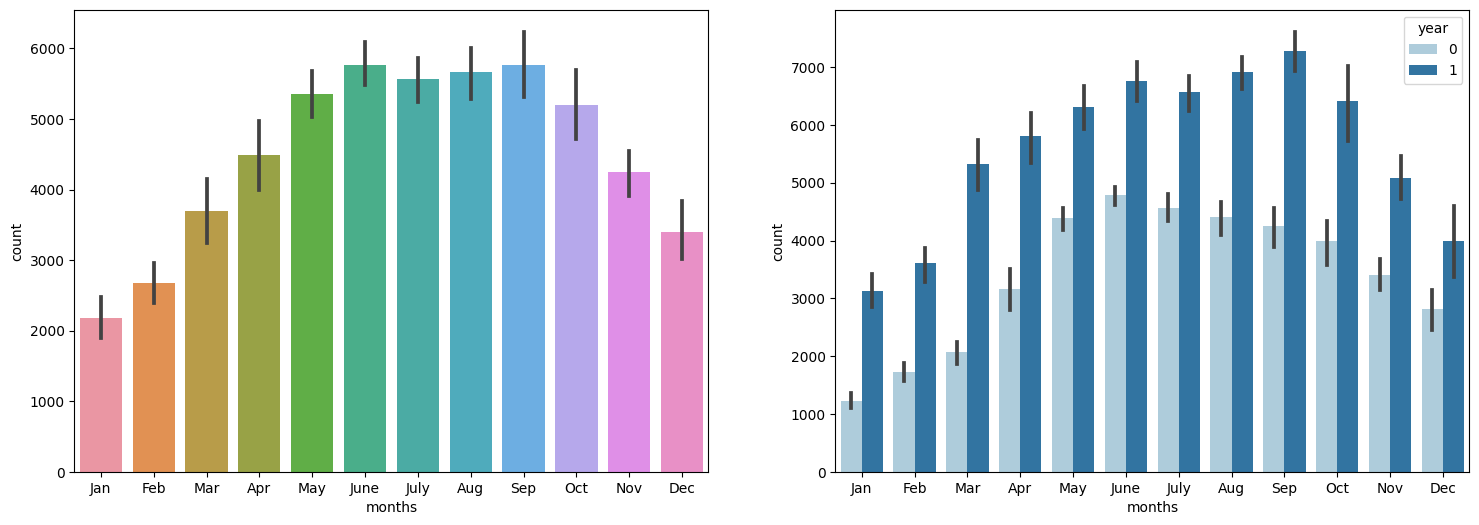

In [29]:
Bike_cat_plots('months', 18,6)

Maximum bike bookings happend from May to Sep, more than 10% each month. More booking happened in 2019 than 2018 during all months.

#### Analyzing Weather Situation

In [30]:
Bike_cat_stats('weathersit')

,sum,mean,count,sum_perc,count_perc
weathersit,,,,,
Clear,2257952,4876.79,463,68.61,63.42
Mist + Cloudy,995024,4044.81,246,30.24,33.70
Light Snow,37869,1803.29,21,1.15,2.88


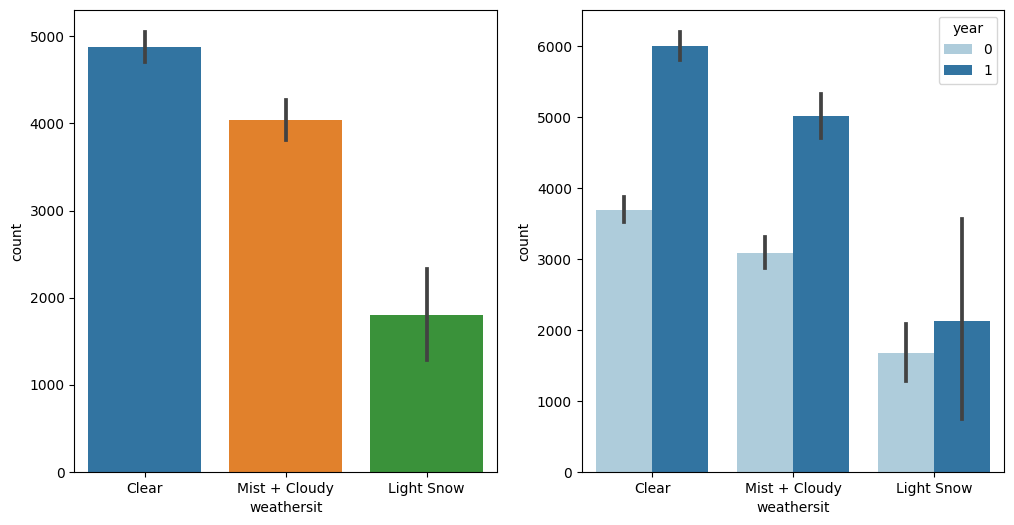

In [31]:
Bike_cat_plots('weathersit', 12,6)

In clear weather, 68.6% of the bookings occurred, while only 30.24% of the bookings took place in misty weather. Light rain and snow resulted in very few bookings. Furthermore, in all seasons, there were more bookings in 2019 than in 2018.

#### Analyzing Weekday

In [32]:
Bike_cat_stats('weekday')

,sum,mean,count,sum_perc,count_perc
weekday,,,,,
Thu,487923,4691.57,104,14.83,14.25
Sun,485235,4665.72,104,14.74,14.25
Sat,481176,4626.69,104,14.62,14.25
Fri,478132,4597.42,104,14.53,14.25
Wed,462276,4444.96,104,14.05,14.25
Tue,448822,4274.50,105,13.64,14.38
Mon,447281,4259.82,105,13.59,14.38


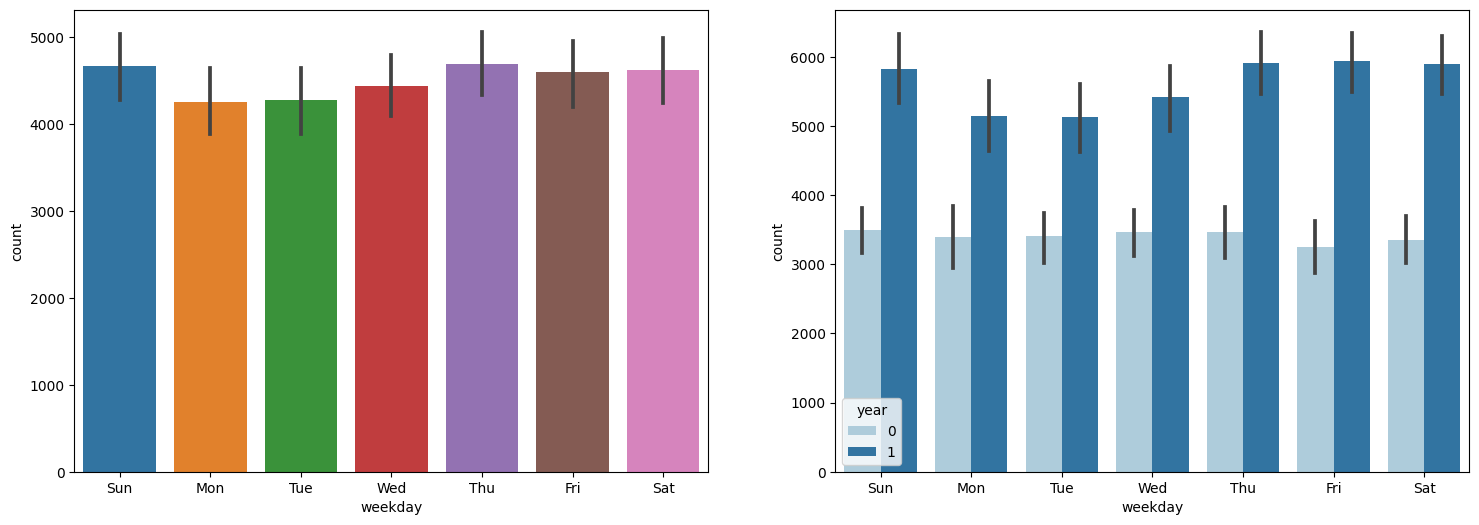

In [33]:
Bike_cat_plots('weekday',18,6)

Bookings made on weekdays are distributed fairly evenly, accounting for approximately 14%. As noted earlier, the trend continues, with more bookings in 2019 compared to 2018.

#### Analyzing Workingday

In [34]:
Bike_cat_stats('workingday')

,sum,mean,count,sum_perc,count_perc
workingday,,,,,
1,2253988,4472.20,504,68.49,69.04
0,1036857,4587.86,226,31.51,30.96


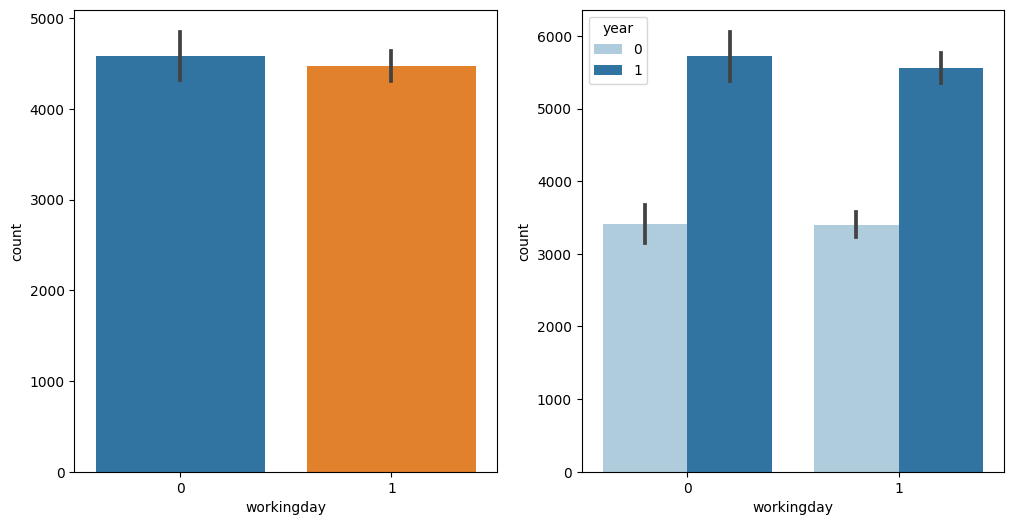

In [35]:
Bike_cat_plots('workingday', 12,6)

Nearly 69% of bike bookings occurred on working days, and 2019 witnessed a higher number of bookings compared to 2018.

#### Analyzing Holiday

In [36]:
Bike_cat_stats('holiday')

,sum,mean,count,sum_perc,count_perc
holiday,,,,,
0,3212410,4530.9,709,97.62,97.12
1,78435,3735.0,21,2.38,2.88


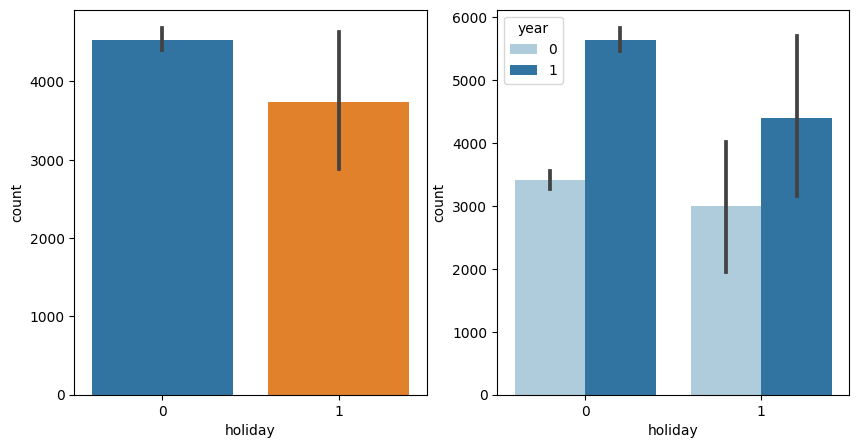

In [37]:
Bike_cat_plots('holiday', 10,5)

Approximately 97% of bike rentals occurred outside of holiday periods. Similarly, 2019 recorded more bookings than 2018.

#### Analyzing Year

In [38]:
Bike_cat_stats('year')

,sum,mean,count,sum_perc,count_perc
year,,,,,
1,2047742,5610.25,365,62.23,50.0
0,1243103,3405.76,365,37.77,50.0


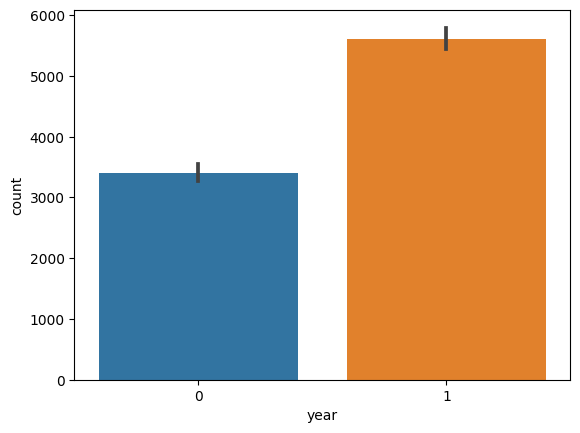

In [39]:
sns.barplot(x = 'year', y = 'count', data= Bike)
plt.show()

There was a substantial increase in demand in 2019 compared to 2018.


---



# Data Preparation

## Creating Dummy variables


In [40]:
# Creating Dummy Variable
months=pd.get_dummies(Bike.months,drop_first=True)
weekdays=pd.get_dummies(Bike.weekday,drop_first=True)
weather_sit=pd.get_dummies(Bike.weathersit,drop_first=True)
seasons=pd.get_dummies(Bike.season,drop_first=True)

In [41]:
# Merging the dataframe

Bike=pd.concat([months,weekdays,weather_sit,seasons,Bike], axis=1)
Bike.head()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,instant,date,season,year,months,holiday,weekday,workingday,weathersit,temp,atemp,humidity,windspeed,casual,registered,count
0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,2018-01-01,Spring,0,Jan,0,Mon,1,Mist + Cloudy,14.110847,18.18125,80.5833,10.749882,331,654,985
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,2,2018-02-01,Spring,0,Jan,0,Tue,1,Mist + Cloudy,14.902598,17.68695,69.6087,16.652113,131,670,801
2,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,3,2018-03-01,Spring,0,Jan,0,Wed,1,Clear,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,4,2018-04-01,Spring,0,Jan,0,Thu,1,Clear,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,5,2018-05-01,Spring,0,Jan,0,Fri,1,Clear,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [42]:
Bike.shape

(730, 38)

In [43]:
# Dropping unwanted columns that have been replaced by dummy variables

Bike.drop(['season','months','weekday','weathersit'], axis=1, inplace = True)

In [44]:
# Dropping other unwanted columns
Bike.drop(['date','instant','casual','registered'], axis=1, inplace = True)

In [45]:
Bike.head()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,14.110847,18.18125,80.5833,10.749882,985
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,14.902598,17.68695,69.6087,16.652113,801
2,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,8.050924,9.47025,43.7273,16.636703,1349
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,8.200000,10.60610,59.0435,10.739832,1562
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,9.305237,11.46350,43.6957,12.522300,1600


In [46]:
Bike.shape

(730, 30)

In [47]:
Bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 30 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Feb            730 non-null    uint8  
 1   Mar            730 non-null    uint8  
 2   Apr            730 non-null    uint8  
 3   May            730 non-null    uint8  
 4   June           730 non-null    uint8  
 5   July           730 non-null    uint8  
 6   Aug            730 non-null    uint8  
 7   Sep            730 non-null    uint8  
 8   Oct            730 non-null    uint8  
 9   Nov            730 non-null    uint8  
 10  Dec            730 non-null    uint8  
 11  Mon            730 non-null    uint8  
 12  Tue            730 non-null    uint8  
 13  Wed            730 non-null    uint8  
 14  Thu            730 non-null    uint8  
 15  Fri            730 non-null    uint8  
 16  Sat            730 non-null    uint8  
 17  Mist + Cloudy  730 non-null    uint8  
 18  Light Snow

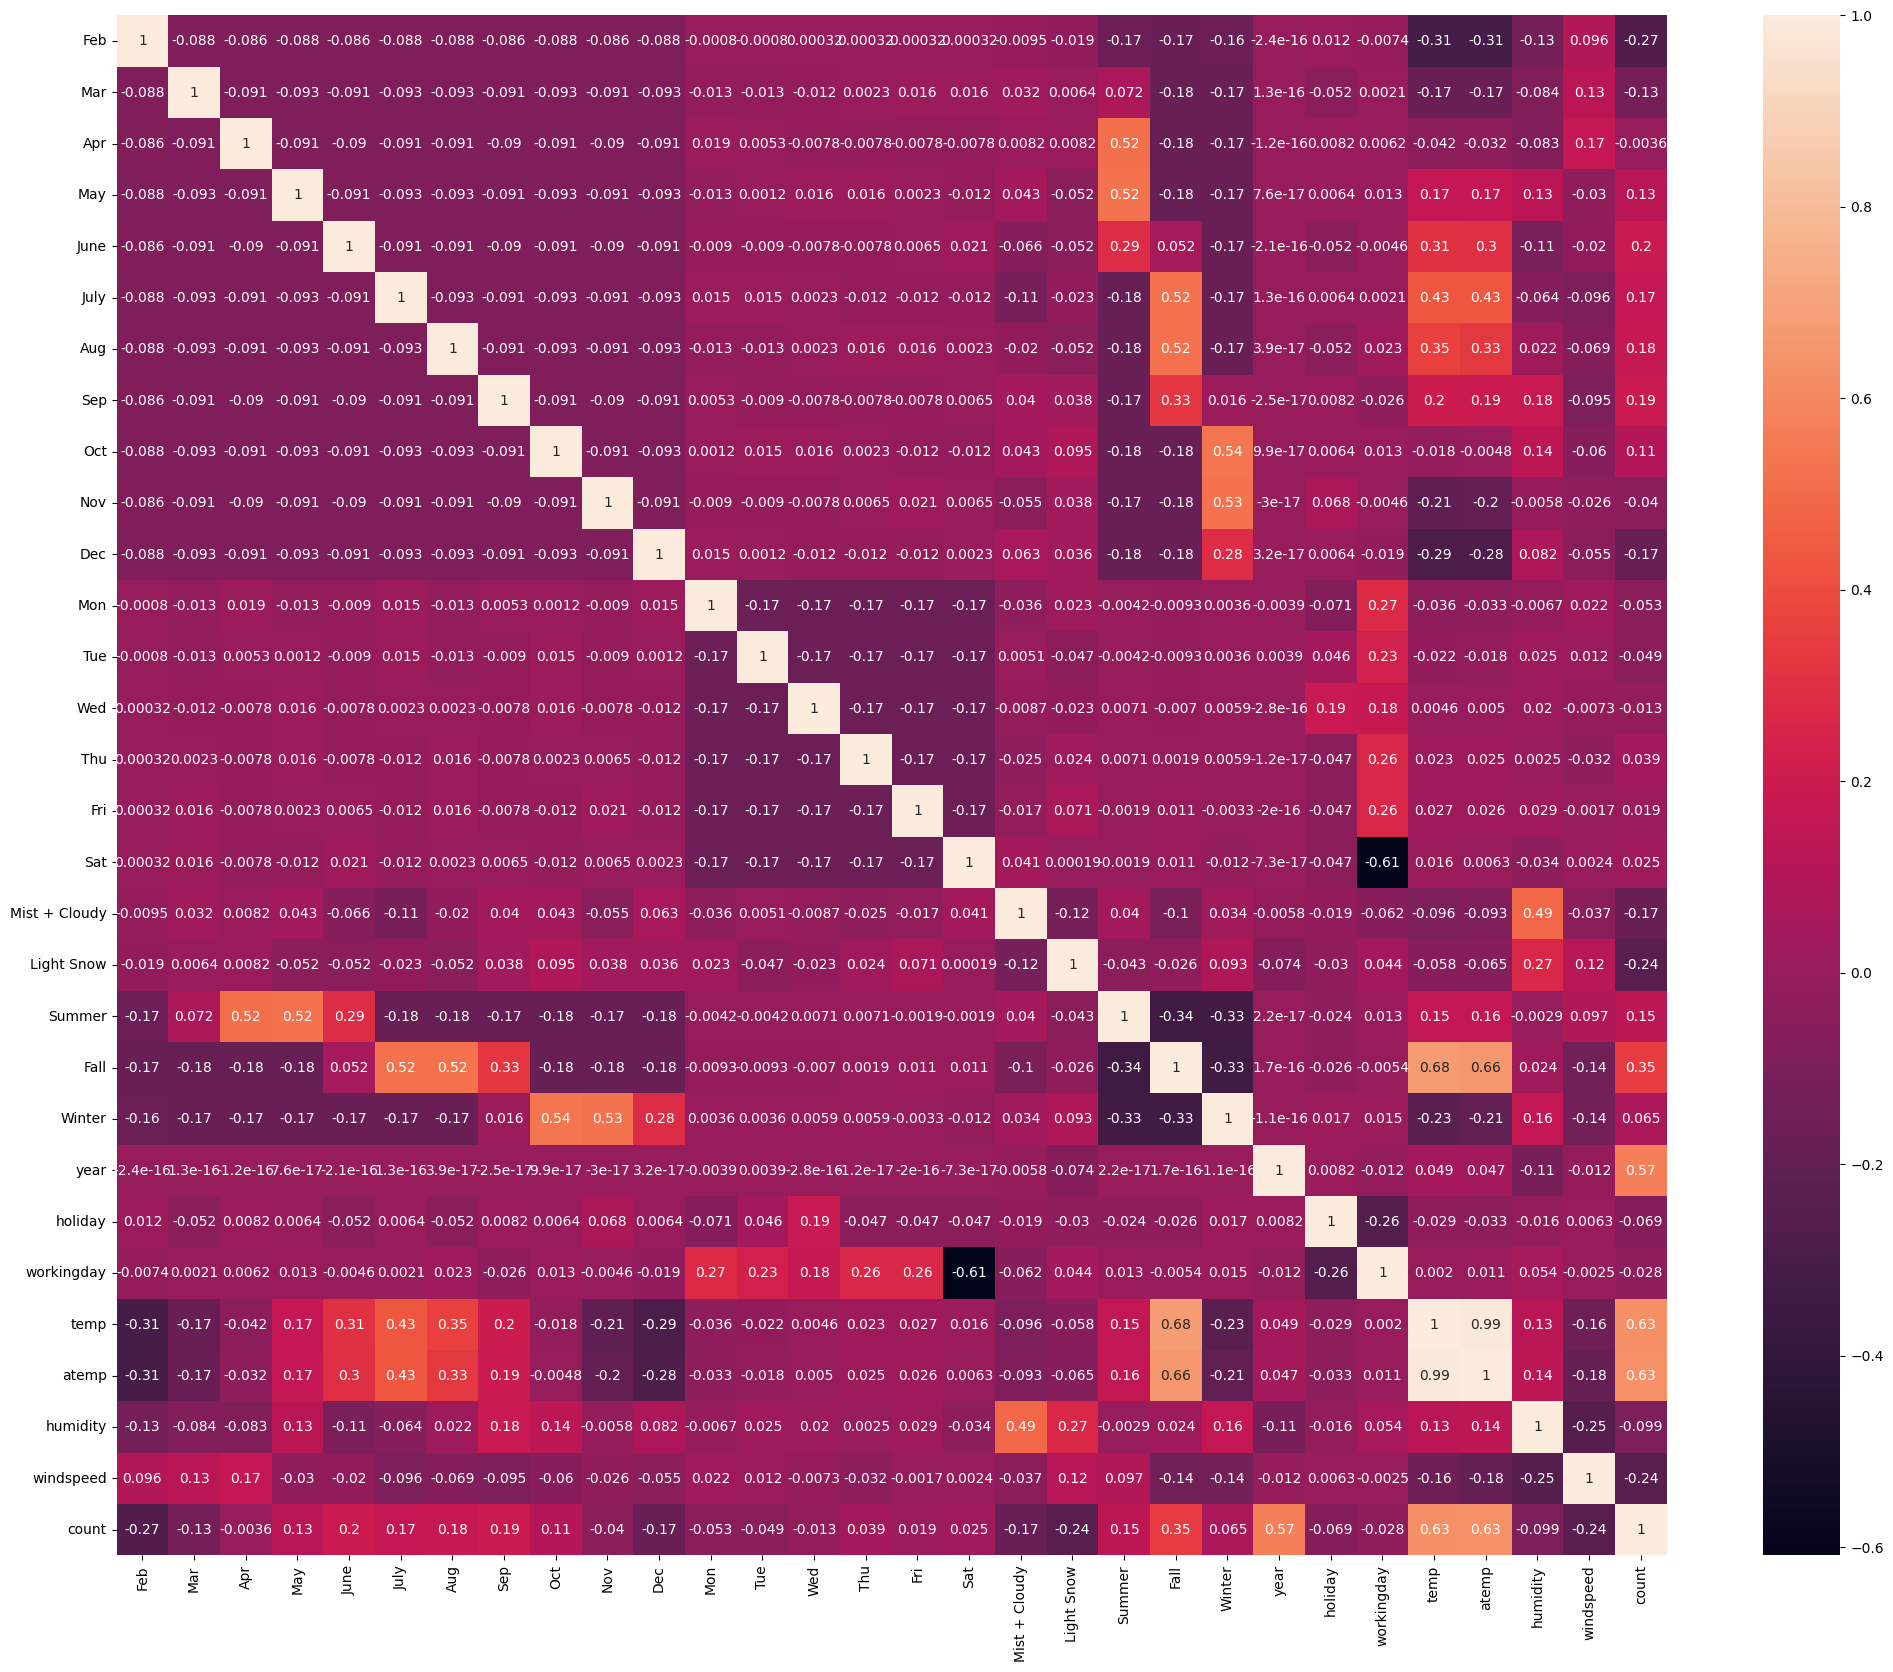

In [48]:
plt.figure(figsize=(25, 20))
sns.heatmap(Bike.corr(), annot = True)
plt.show()

The following conclusions can be drawn from the heatmap:
<ul>
    <li> Multicollinearity is evident among the variables.</li>
    <li> One can select either 'temp' or 'atemp' due to their high multicollinearity.</li>
    <li> 'temp' and 'atemp' exhibit a strong correlation with 'count'.</li>
    <li> 'Fall' shows a positive correlation with 'count'.</li>
    <li> 'Mist + Cloudy' weather and humidity are correlated.</li>
    <li> Months and their corresponding weather conditions are correlated as expected.</li>
    <li> Humidity demonstrates a strong correlation with weather conditions.</li>
</ul>



---



## Splitting the Data into Training and Testing Datasets

Prior to constructing the model, the initial steps involve splitting the data into training and testing sets and scaling the features.


In [49]:
from sklearn.model_selection import train_test_split

# We specify this to ensure that the training and testing datasets consistently have the same set of rows.
Bike_train, Bike_test = train_test_split(Bike, train_size = 0.7, random_state = 100)

In [50]:
#Rows and columns after splitting
print(Bike_train.shape)
print(Bike_test.shape)

(510, 30)
(220, 30)


In [51]:
Bike_train.describe()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
count,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000
mean,0.066667,0.098039,0.078431,0.084314,0.076471,0.076471,0.096078,0.080392,0.084314,0.086275,0.084314,0.154902,0.152941,0.135294,0.143137,0.147059,0.129412,0.345098,0.029412,0.247059,0.262745,0.247059,0.507843,0.025490,0.711765,20.108257,23.500287,63.123710,12.834912,4485.337255
std,0.249689,0.297660,0.269113,0.278131,0.266010,0.266010,0.294988,0.272166,0.278131,0.281045,0.278131,0.362166,0.360284,0.342373,0.350557,0.354512,0.335985,0.475867,0.169124,0.431725,0.440557,0.431725,0.500429,0.157763,0.453386,7.431626,8.090963,14.153170,5.292031,1950.666077
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.424346,3.953480,0.000000,2.834381,22.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.606865,16.603063,52.270825,9.041918,3120.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,20.277923,24.131150,63.437500,12.083182,4530.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,26.615847,30.177700,73.250025,15.750879,5973.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.328347,42.044800,97.041700,34.000021,8714.000000


In [52]:
Bike_test.describe()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
count,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000
mean,0.100000,0.054545,0.090909,0.086364,0.095455,0.104545,0.059091,0.086364,0.086364,0.072727,0.086364,0.118182,0.122727,0.159091,0.140909,0.131818,0.172727,0.318182,0.027273,0.263636,0.245455,0.236364,0.481818,0.036364,0.640909,20.808400,24.250312,61.934025,12.598352,4560.559091
std,0.300684,0.227609,0.288135,0.281541,0.294512,0.306665,0.236333,0.281541,0.281541,0.260281,0.281541,0.323559,0.328872,0.366595,0.348721,0.339064,0.378873,0.466833,0.163248,0.441609,0.431338,0.425817,0.500809,0.187620,0.480828,7.672796,8.281075,14.429542,4.973534,1904.968544
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.957390,4.941955,25.416700,1.500244,441.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.119375,17.090025,51.354200,9.031466,3312.750000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,20.790424,24.700000,60.708350,12.188004,4582.500000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,27.299153,31.124313,72.179375,15.385361,5913.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,34.815847,41.318550,97.250000,27.999836,8395.000000


### Rescaling the bike_train dataframe

Achieving uniform scaling of all variables is crucial for enhancing the model's interpretability. Two common methods for achieving this are:

* **Min-Max scaling (Normalization):** This method scales the variables to a range between 0 and 1.

* **Standardization:** This approach centers the data with a mean of 0 and a standard deviation of 1, making the coefficients of the variables comparable on the same scale.

#### Min-Max scaling

In [53]:
#Normalisation = (x-xmin)/(x max-x min)
#Standardisation= (x-mu)/ sigma

# Importing the library
from sklearn.preprocessing import MinMaxScaler

In [54]:
#Instantiating an object
scaler = MinMaxScaler()

In [55]:
#Creating a list of numeric variables
num_vars=['temp','humidity','windspeed','count']

In [56]:
#Fit on data
Bike_train[num_vars] = scaler.fit_transform(Bike_train[num_vars])
Bike_train.head()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
576,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0.815169,33.1448,0.725633,0.264686,0.827658
426,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.442393,20.6746,0.640189,0.255342,0.465255
728,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0.245101,11.5850,0.498067,0.663106,0.204096
482,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0.395666,18.8752,0.504508,0.188475,0.482973
111,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0.345824,16.0977,0.751824,0.380981,0.191095


In [57]:
#Checking numeric variables(min and max) after scaling
Bike_train.describe()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
count,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000
mean,0.066667,0.098039,0.078431,0.084314,0.076471,0.076471,0.096078,0.080392,0.084314,0.086275,0.084314,0.154902,0.152941,0.135294,0.143137,0.147059,0.129412,0.345098,0.029412,0.247059,0.262745,0.247059,0.507843,0.025490,0.711765,0.537440,23.500287,0.650480,0.320883,0.513499
std,0.249689,0.297660,0.269113,0.278131,0.266010,0.266010,0.294988,0.272166,0.278131,0.281045,0.278131,0.362166,0.360284,0.342373,0.350557,0.354512,0.335985,0.475867,0.169124,0.431725,0.440557,0.431725,0.500429,0.157763,0.453386,0.225858,8.090963,0.145846,0.169803,0.224421
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.953480,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.339853,16.603063,0.538643,0.199179,0.356420
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.542596,24.131150,0.653714,0.296763,0.518638
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.735215,30.177700,0.754830,0.414447,0.684710
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,42.044800,1.000000,1.000000,1.000000


**All the numerical variables have been scaled to a range between 0 and 1.**

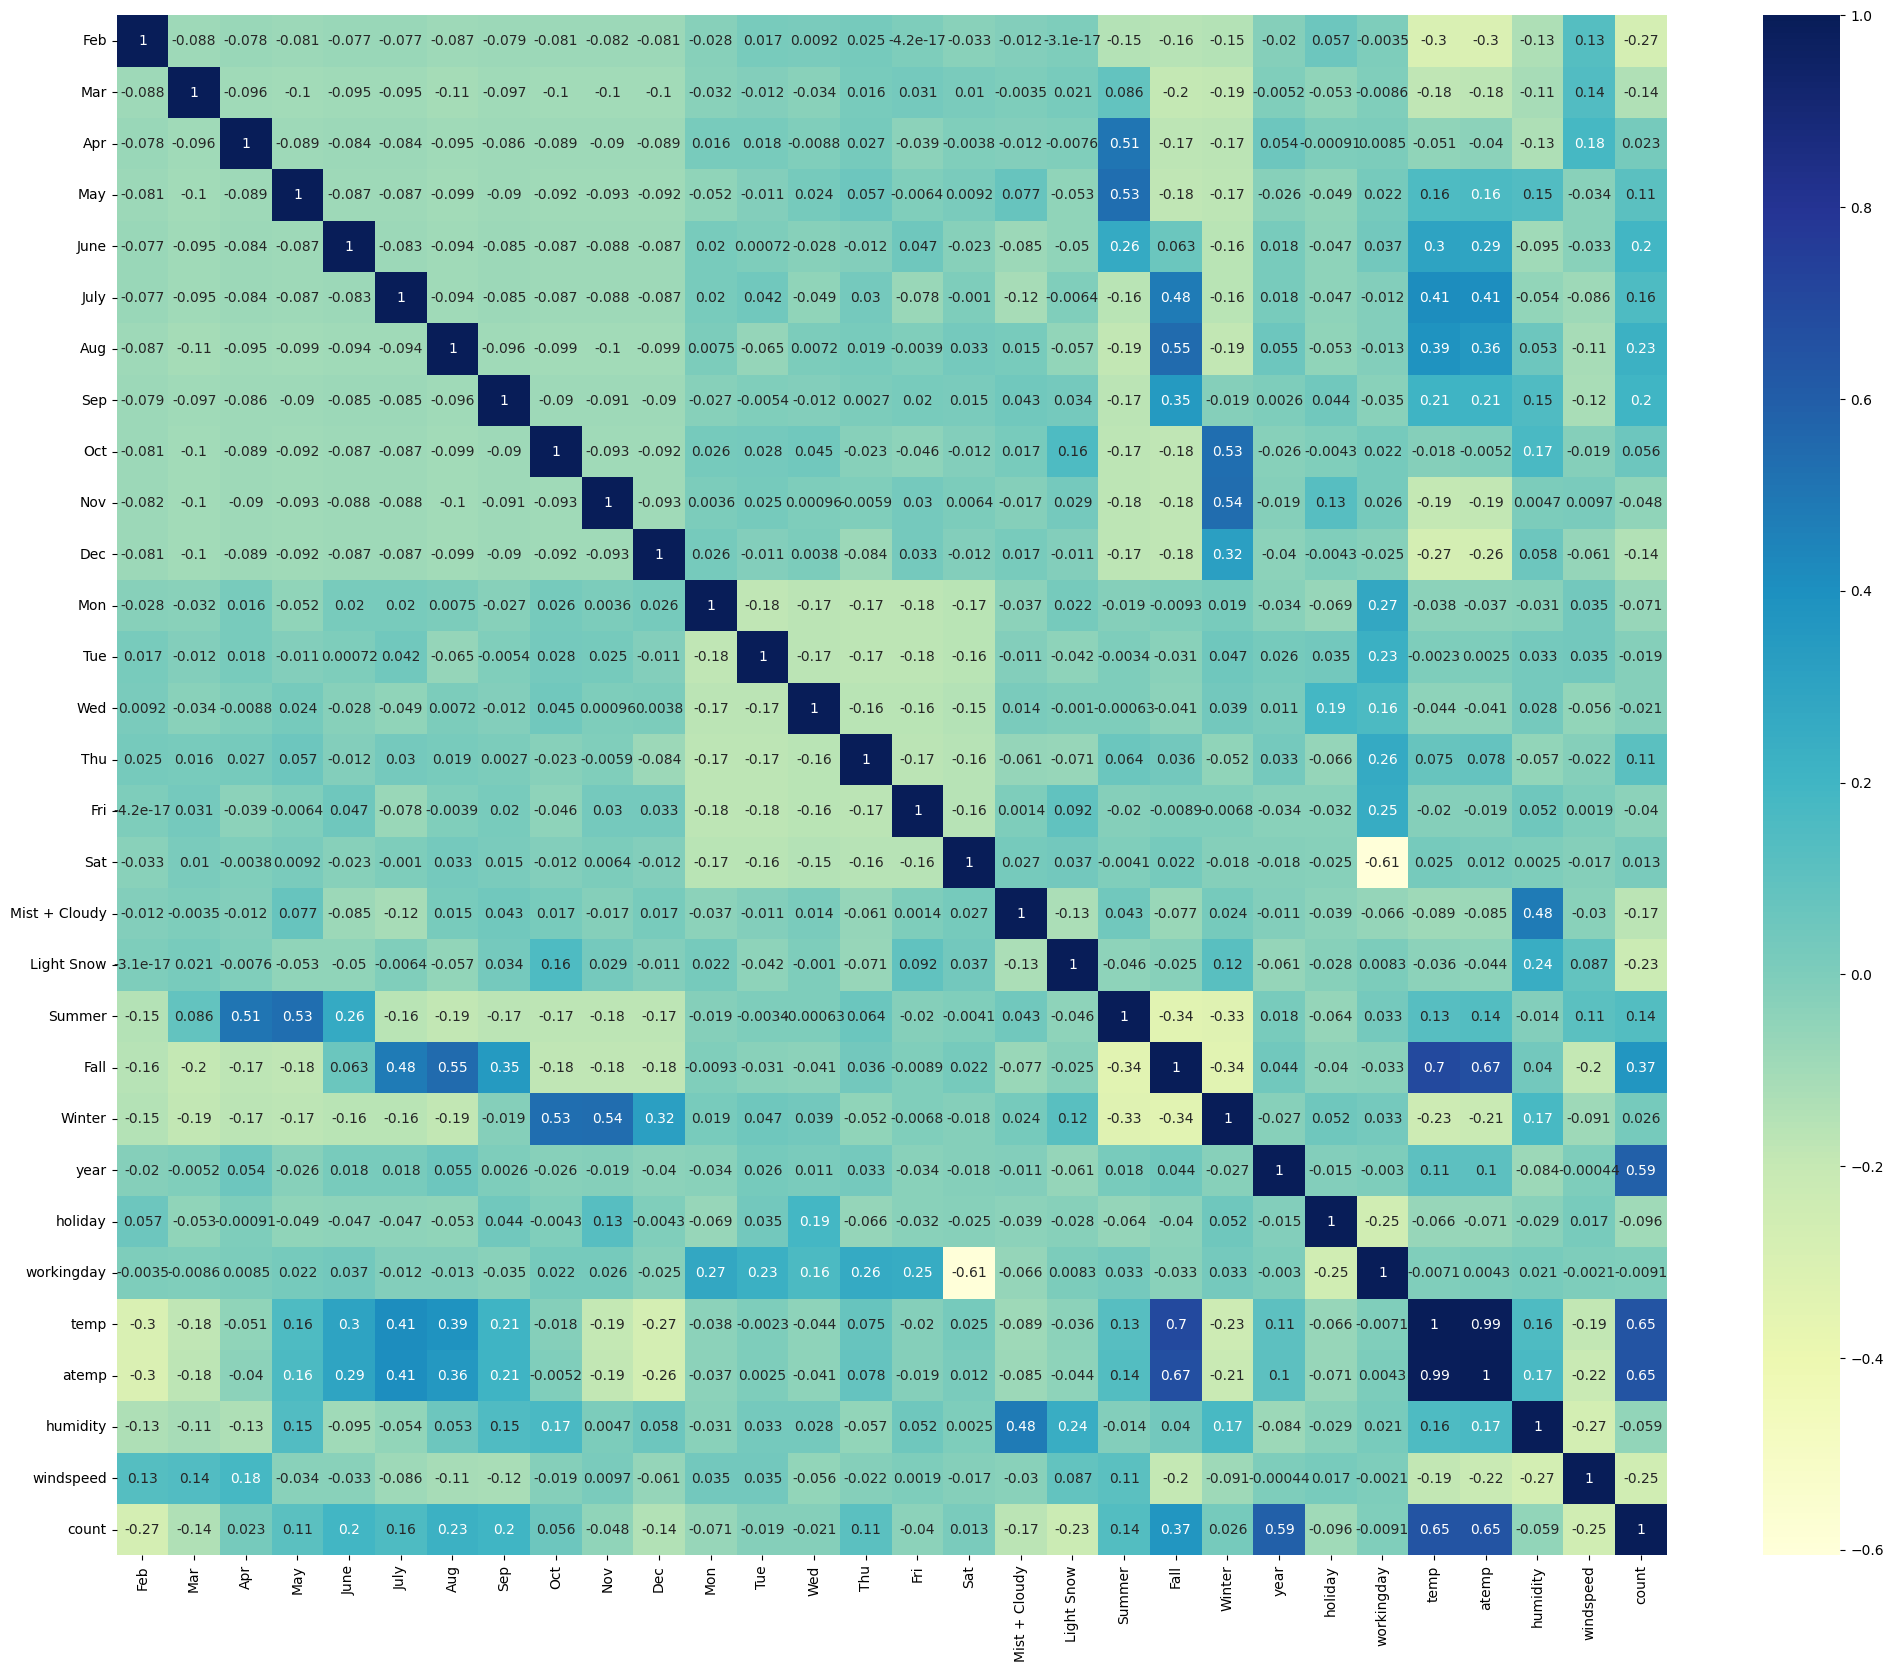

In [58]:
# Examining the correlation coefficients to identify highly correlated variables after scaling.
# We anticipate that there will be minimal to no multicollinearity among the predictors.

plt.figure(figsize=(25, 20))
sns.heatmap(Bike_train.corr(),cmap='YlGnBu',annot = True)
plt.show()

Multicollinearity: Assumes that predictors exhibit no correlation with each other.

The heatmap reveals correlations between the 'temp' and 'year' variables with the 'count' variable.


---



# Linear Model Building

In [59]:
# Building the model

y_train = Bike_train.pop('count')
X_train = Bike_train

In [60]:
X_train

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed
576,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0.815169,33.14480,0.725633,0.264686
426,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.442393,20.67460,0.640189,0.255342
728,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0.245101,11.58500,0.498067,0.663106
482,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0.395666,18.87520,0.504508,0.188475
111,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0.345824,16.09770,0.751824,0.380981
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,0.863973,35.35440,0.679690,0.187140
53,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0.202618,12.28585,0.435939,0.111379
350,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0.248216,12.46855,0.577930,0.431816
79,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0.462664,20.48675,0.759870,0.529881


## Recursive Feature Elimination:

We will utilize the LinearRegression function from SciKit Learn because of its compatibility with Recursive Feature Elimination (RFE).

In [61]:
# Importing the functions
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

In [62]:
# Running RFE with the output number of the variable equal to 20
lm = LinearRegression()
lm.fit(X_train, y_train)

# running RFE
rfe = RFE(estimator=lm, n_features_to_select=20)
rfe =rfe.fit(X_train, y_train)

In [63]:
list(zip(X_train.columns, rfe.support_, rfe.ranking_))

[('Feb', False, 5),
 ('Mar', True, 1),
 ('Apr', True, 1),
 ('May', True, 1),
 ('June', True, 1),
 ('July', False, 6),
 ('Aug', True, 1),
 ('Sep', True, 1),
 ('Oct', True, 1),
 ('Nov', False, 7),
 ('Dec', False, 8),
 ('Mon', False, 3),
 ('Tue', False, 4),
 ('Wed', False, 2),
 ('Thu', True, 1),
 ('Fri', True, 1),
 ('Sat', False, 9),
 ('Mist + Cloudy', True, 1),
 ('Light Snow', True, 1),
 ('Summer', True, 1),
 ('Fall', True, 1),
 ('Winter', True, 1),
 ('year', True, 1),
 ('holiday', True, 1),
 ('workingday', True, 1),
 ('temp', True, 1),
 ('atemp', False, 10),
 ('humidity', True, 1),
 ('windspeed', True, 1)]

In [64]:
#Columns where RFE support is True
col = X_train.columns[rfe.support_]
col

Index(['Mar', 'Apr', 'May', 'June', 'Aug', 'Sep', 'Oct', 'Thu', 'Fri',
       'Mist + Cloudy', 'Light Snow', 'Summer', 'Fall', 'Winter', 'year',
       'holiday', 'workingday', 'temp', 'humidity', 'windspeed'],
      dtype='object')

In [65]:
#Columns where RFE support is False
X_train.columns[~rfe.support_]

Index(['Feb', 'July', 'Nov', 'Dec', 'Mon', 'Tue', 'Wed', 'Sat', 'atemp'], dtype='object')

# Manual Model Development using statsmodel

In [66]:
# Creating X_test dataframe with RFE selected variables
X_train_rfe = X_train[col]


In [67]:
# Adding a constant variable
import statsmodels.api as sm
X_train_rfe = sm.add_constant(X_train_rfe)


### Model 1

In [68]:
# Running the linear model
lm = sm.OLS(y_train,X_train_rfe.astype(float)).fit()

In [69]:
print(lm.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.849
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                     137.5
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          3.87e-186
Time:                        10:24:09   Log-Likelihood:                 521.09
No. Observations:                 510   AIC:                            -1000.
Df Residuals:                     489   BIC:                            -911.3
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.2452      0.028      8.825

**Checking VIF**
The Variance Inflation Factor (VIF) provides a quantitative assessment of the degree of correlation among the feature variables. It is a critical parameter for evaluating the assumptions of our linear model. The formula for calculating the VIF is as follows:

### $ VIF_i = \frac{1}{1 - {R_i}^2} $

In [70]:
#Dropping the constant term B0
X_train_rfe = X_train_rfe.drop(['const'], axis=1)

In [71]:
# Calculate the VIFs for the new model
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
X = X_train_rfe
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
17,temp,29.13
18,humidity,18.12
12,Fall,9.03
11,Summer,7.50
16,workingday,4.33
19,windspeed,4.03
2,May,3.73
1,Apr,3.33
13,Winter,3.22
3,June,2.53


### Model 2

In [72]:
#Dropping "Apr" dues to high p-value and considerably lower VIF
X_train_new1 = X_train_rfe.drop(["Apr"], axis = 1)


Rebuilding model withour 'Apr'.

In [73]:
#Build a model
X_train_lm1 = sm.add_constant(X_train_new1)
lm1 = sm.OLS(y_train,X_train_lm1.astype(float)).fit()
print(lm1.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     144.2
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          1.09e-186
Time:                        10:24:09   Log-Likelihood:                 519.79
No. Observations:                 510   AIC:                            -999.6
Df Residuals:                     490   BIC:                            -914.9
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.2485      0.028      8.957

In [74]:
#Drop the constant term B0
X_train_lm1 = X_train_lm1.drop(['const'], axis=1)

In [75]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new1
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
16,temp,28.84
17,humidity,18.08
11,Fall,9.03
15,workingday,4.33
18,windspeed,3.95
10,Summer,3.83
12,Winter,3.18
8,Mist + Cloudy,2.23
13,year,2.06
1,May,1.98


Dropping 'humidity' variable due to very high VIF.

### Model 3

In [76]:
#Dropping 'humidity'
X_train_new2 = X_train_new1.drop(["humidity"], axis = 1)

rebuilding model without 'humidity'

In [77]:
#Build a model
X_train_lm2 = sm.add_constant(X_train_new2)
lm2 = sm.OLS(y_train,X_train_lm2.astype(float)).fit()
print(lm2.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.842
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     145.6
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          1.21e-183
Time:                        10:24:10   Log-Likelihood:                 509.83
No. Observations:                 510   AIC:                            -981.7
Df Residuals:                     491   BIC:                            -901.2
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1568      0.019      8.364

In [78]:
#Drop the constant term B0
X_train_lm2 = X_train_lm2.drop(['const'], axis=1)

In [79]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new2
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
16,temp,19.63
11,Fall,8.61
15,workingday,3.88
10,Summer,3.79
17,windspeed,3.78
12,Winter,3.08
13,year,2.06
1,May,1.98
3,Aug,1.96
2,June,1.65


Dropping 'June' variable due to very high p-value and low VIF.

### Model 4

In [80]:
#Dropping 'June'
X_train_new3 = X_train_new2.drop(["June"], axis = 1)

rebuilding model without 'June'

In [81]:
#Build a model
X_train_lm3 = sm.add_constant(X_train_new3)
lm3 = sm.OLS(y_train,X_train_lm3.astype(float)).fit()
print(lm3.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.841
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     153.6
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          3.26e-184
Time:                        10:24:10   Log-Likelihood:                 508.55
No. Observations:                 510   AIC:                            -981.1
Df Residuals:                     492   BIC:                            -904.9
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1529      0.019      8.216

In [82]:
#Drop the constant term B0
X_train_lm3 = X_train_lm3.drop(['const'], axis=1)

In [83]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new3
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
15,temp,17.13
10,Fall,8.47
14,workingday,3.87
9,Summer,3.71
16,windspeed,3.70
11,Winter,2.99
12,year,2.05
2,Aug,1.85
1,May,1.67
4,Oct,1.63


### Model 5

In [84]:
#Dropping 'May'
X_train_new4 = X_train_new3.drop(["May"], axis = 1)

rebuilding model without 'May'

In [85]:
#Build a model
X_train_lm4 = sm.add_constant(X_train_new4)
lm4 = sm.OLS(y_train,X_train_lm4.astype(float)).fit()
print(lm4.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.841
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     163.2
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          3.78e-185
Time:                        10:24:10   Log-Likelihood:                 508.12
No. Observations:                 510   AIC:                            -982.2
Df Residuals:                     493   BIC:                            -910.3
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1524      0.019      8.196

In [86]:
#Drop the constant term B0
X_train_lm4 = X_train_lm4.drop(['const'], axis=1)

In [87]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new4
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
14,temp,16.22
9,Fall,8.16
13,workingday,3.87
15,windspeed,3.64
8,Summer,3.51
10,Winter,2.94
11,year,2.04
1,Aug,1.85
3,Oct,1.62
6,Mist + Cloudy,1.51


Now, dropping 'Fri' due to high p-value and low VIF.

### Model 6

In [88]:
#Dropping 'Fri'
X_train_new5 = X_train_new4.drop(["Fri"], axis = 1)

rebuilding model without 'Fri'

In [89]:
#Build a model
X_train_lm5 = sm.add_constant(X_train_new5)
lm5 = sm.OLS(y_train,X_train_lm5.astype(float)).fit()
print(lm5.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.840
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     173.2
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          1.32e-185
Time:                        10:24:10   Log-Likelihood:                 506.52
No. Observations:                 510   AIC:                            -981.0
Df Residuals:                     494   BIC:                            -913.3
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1521      0.019      8.164

In [90]:
#Drop the constant term B0
X_train_lm5 = X_train_lm5.drop(['const'], axis=1)

In [91]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new5
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
13,temp,16.19
8,Fall,8.15
14,windspeed,3.64
7,Summer,3.50
12,workingday,3.44
9,Winter,2.94
10,year,2.04
1,Aug,1.85
3,Oct,1.62
5,Mist + Cloudy,1.51


Now, let's drop features with high VIF.

### Model 7

In [92]:
#Dropping 'Fall'
X_train_new6 = X_train_new5.drop(["Fall"], axis = 1)

rebuilding model without 'Fall'

In [93]:
#Build a model
X_train_lm6 = sm.add_constant(X_train_new6)
lm6 = sm.OLS(y_train,X_train_lm6.astype(float)).fit()
print(lm6.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.839
Model:                            OLS   Adj. R-squared:                  0.834
Method:                 Least Squares   F-statistic:                     183.7
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          1.10e-185
Time:                        10:24:10   Log-Likelihood:                 503.98
No. Observations:                 510   AIC:                            -978.0
Df Residuals:                     495   BIC:                            -914.5
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1457      0.018      7.884

In [94]:
#Drop the constant term B0
X_train_lm6 = X_train_lm6.drop(['const'], axis=1)

In [95]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new6
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
12,temp,5.81
13,windspeed,3.56
11,workingday,3.42
8,Winter,2.05
9,year,2.02
7,Summer,1.83
1,Aug,1.61
3,Oct,1.59
5,Mist + Cloudy,1.50
2,Sep,1.34


Now, dropping 'Thu'.

### Model 8

In [96]:
#Dropping 'Thu'
X_train_new7 = X_train_new6.drop(["Thu"], axis = 1)

rebuilding model without 'Thu'

In [97]:
#Build a model
X_train_lm7 = sm.add_constant(X_train_new7)
lm7 = sm.OLS(y_train,X_train_lm7.astype(float)).fit()
print(lm7.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     196.7
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          3.91e-186
Time:                        10:24:10   Log-Likelihood:                 502.30
No. Observations:                 510   AIC:                            -976.6
Df Residuals:                     496   BIC:                            -917.3
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1449      0.019      7.827

In [98]:
#Drop the constant term B0
X_train_lm7 = X_train_lm7.drop(['const'], axis=1)

In [99]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new7
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
11,temp,5.80
12,windspeed,3.55
10,workingday,3.19
7,Winter,2.05
8,year,2.02
6,Summer,1.83
1,Aug,1.61
3,Oct,1.59
4,Mist + Cloudy,1.50
2,Sep,1.34


Let's drop 'Mar' due to high p-value and low VIF.

### Model 9

In [100]:
#Dropping 'Mar'
X_train_new8 = X_train_new7.drop(["Mar"], axis = 1)

rebuilding model without 'Mar'

In [101]:
#Build a model
X_train_lm8 = sm.add_constant(X_train_new8)
lm8 = sm.OLS(y_train,X_train_lm8.astype(float)).fit()
print(lm8.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     212.1
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          1.03e-186
Time:                        10:24:10   Log-Likelihood:                 500.89
No. Observations:                 510   AIC:                            -975.8
Df Residuals:                     497   BIC:                            -920.7
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1511      0.018      8.312

In [102]:
#Drop the constant term B0
X_train_lm8 = X_train_lm8.drop(['const'], axis=1)

In [103]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new8
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
10,temp,5.80
11,windspeed,3.39
9,workingday,3.17
6,Winter,2.01
7,year,2.01
5,Summer,1.83
0,Aug,1.59
2,Oct,1.59
3,Mist + Cloudy,1.49
1,Sep,1.34


Now, dropping 'workingday'.

### Model 10

In [104]:
#Dropping 'workingday'
X_train_new9 = X_train_new8.drop(["workingday"], axis = 1)

rebuilding model without 'workingday'

In [105]:
#Build a model
X_train_lm9 = sm.add_constant(X_train_new9)
lm9 = sm.OLS(y_train,X_train_lm9.astype(float)).fit()
print(lm9.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.835
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     228.9
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          9.45e-187
Time:                        10:24:11   Log-Likelihood:                 498.15
No. Observations:                 510   AIC:                            -972.3
Df Residuals:                     498   BIC:                            -921.5
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1346      0.017      8.014

In [106]:
#Drop the constant term B0
X_train_lm9 = X_train_lm9.drop(['const'], axis=1)

In [107]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new9
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
9,temp,5.11
10,windspeed,3.11
7,year,2.00
6,Winter,1.93
5,Summer,1.83
0,Aug,1.59
2,Oct,1.59
3,Mist + Cloudy,1.49
1,Sep,1.34
4,Light Snow,1.10


Lastly, dropping 'Oct'.

### Model 11

In [108]:
#Dropping 'Oct'
X_train_new10 = X_train_new9.drop(["Oct"], axis = 1)

rebuilding model without 'Oct'

In [109]:
#Build a model
X_train_lm10 = sm.add_constant(X_train_new10)
lm10 = sm.OLS(y_train,X_train_lm10.astype(float)).fit()
print(lm10.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     250.5
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          2.62e-187
Time:                        10:24:11   Log-Likelihood:                 496.61
No. Observations:                 510   AIC:                            -971.2
Df Residuals:                     499   BIC:                            -924.6
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.1307      0.017      7.837

In [110]:
#Drop the constant term B0
X_train_lm10 = X_train_lm10.drop(['const'], axis=1)

In [111]:
# Calculate the VIFs for the new model
vif = pd.DataFrame()
X = X_train_new10
vif['Features'] = X.columns
X = X.astype(float)
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
8,temp,5.01
9,windspeed,3.10
6,year,2.00
4,Summer,1.82
0,Aug,1.58
2,Mist + Cloudy,1.49
5,Winter,1.48
1,Sep,1.31
3,Light Snow,1.08
7,holiday,1.04


Our model is now ready for use. The p-values indicate the significance of the variables, and the VIF values represent the degree of correlation between variables. Based on these two criteria, we've determined which variables to retain.

Both the VIFs and p-values fall within acceptable ranges, allowing us to proceed with our regression.

The p-value for each term tests the null hypothesis that the coefficient is zero (no effect). A low p-value (< 0.05) suggests that we can reject the null hypothesis.

A commonly used rule is that a VIF greater than 10 indicates high multicollinearity. In our case, with values under 5 or near 5, we are in good shape and can proceed with regression.

The R-squared value quantifies the strength of the relationship between our model and the dependent variable on a scale of 0 to 100%. In our case, we have an R-squared value of 0.834 or 83.4%.

The adjusted R-squared accounts for the number of terms in the model, and in our case, it is approximately 0.831 or 83.1%.

Now, let's examine one more model by removing the 'temp' variable.

### Model 12

In [112]:
#Dropping 'temp'
X_train_new11 = X_train_new10.drop(["temp"], axis = 1)

rebuilding model without 'temp'

In [113]:
#Build a model
X_train_lm11 = sm.add_constant(X_train_new11)
lm11 = sm.OLS(y_train,X_train_lm11.astype(float)).fit()
print(lm11.summary())

                            OLS Regression Results                            
Dep. Variable:                  count   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.643
Method:                 Least Squares   F-statistic:                     102.8
Date:                Tue, 07 Nov 2023   Prob (F-statistic):          8.51e-108
Time:                        10:24:11   Log-Likelihood:                 306.08
No. Observations:                 510   AIC:                            -592.2
Df Residuals:                     500   BIC:                            -549.8
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.4052      0.017     23.402

In this case, we observe a significant decrease in both R-squared and adjusted R-squared values. Consequently, this model doesn't appear to be a suitable choice.

Hence, our preferred model is lm10.


---



# Analyzing Linear relationship

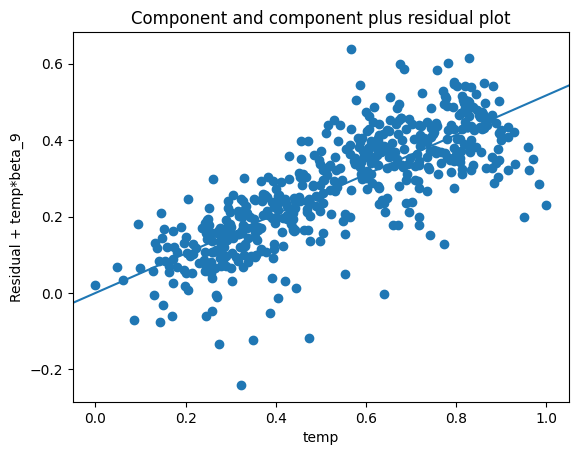

In [114]:
sm.graphics.plot_ccpr(lm10, 'temp')
plt.show()

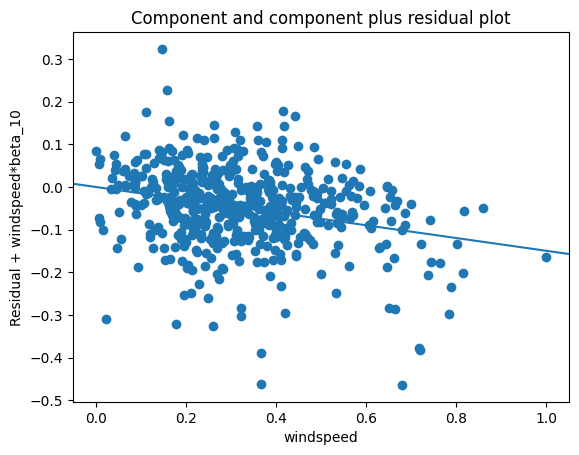

In [115]:
sm.graphics.plot_ccpr(lm10, 'windspeed')
plt.show()

The preceding plots illustrate the relationship between the model and various predictor variables. It's evident that linearity has been effectively maintained.


---



## Residual Analysis of the train data

So, now to check if the error terms are also normally distributed (which is infact, one of the major assumptions of linear regression), let us plot the histogram of the error terms and see what it looks like.

In [116]:
X_train_lm10=sm.add_constant(X_train_lm10)
#X_train_lm10.columns
X_train_lm10

,const,Aug,Sep,Mist + Cloudy,Light Snow,Summer,Winter,year,holiday,temp,windspeed
576,1.0,0,0,0,0,0,0,1,0,0.815169,0.264686
426,1.0,0,0,1,0,0,0,1,0,0.442393,0.255342
728,1.0,0,0,0,0,0,0,1,0,0.245101,0.663106
482,1.0,0,0,1,0,1,0,1,0,0.395666,0.188475
111,1.0,0,0,1,0,1,0,0,0,0.345824,0.380981
...,...,...,...,...,...,...,...,...,...,...,...
578,1.0,1,0,0,0,0,0,1,0,0.863973,0.187140
53,1.0,0,0,0,0,0,0,0,0,0.202618,0.111379
350,1.0,0,0,1,0,0,1,0,0,0.248216,0.431816
79,1.0,0,0,1,0,1,0,0,0,0.462664,0.529881


In [117]:
#y train predicted
y_train_pred = lm10.predict(X_train_lm10)

In [118]:
# Importing the required libraries for plots.
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

<Figure size 640x480 with 0 Axes>

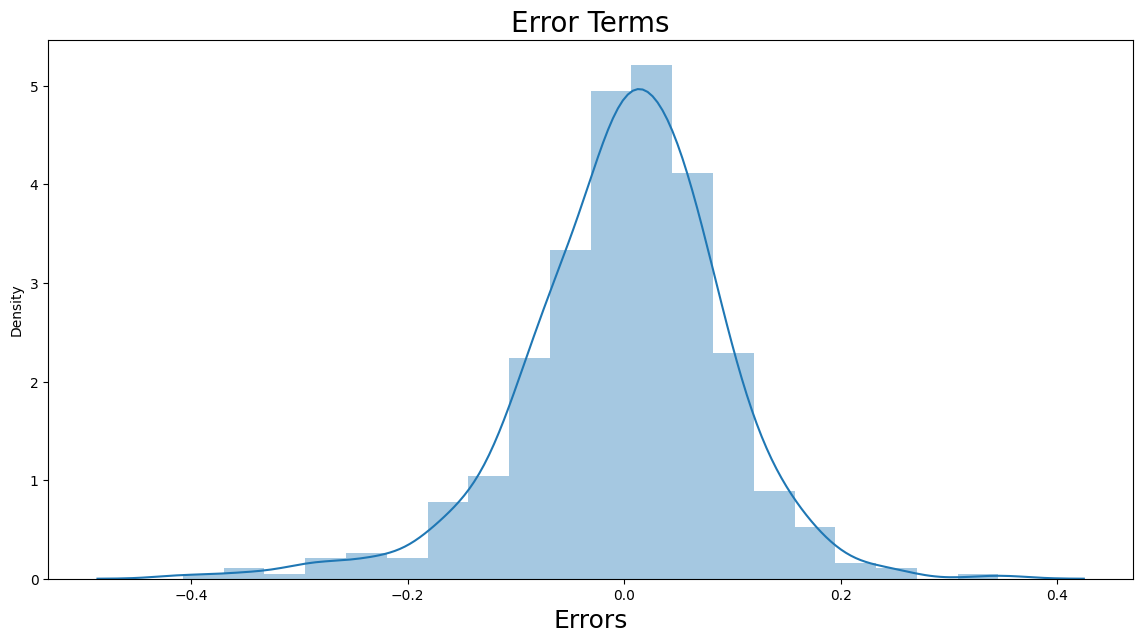

In [119]:
# Plot the histogram of the error terms

fig = plt.figure()
plt.figure(figsize=(14,7))
sns.distplot((y_train - y_train_pred), bins = 20)
plt.title('Error Terms', fontsize = 20)                  # Plot heading
plt.xlabel('Errors', fontsize = 18)  # X-label
plt.show()

**We can see Error terms are normally distributed**

# Multicolinearity

In [120]:
X_train_lm10.columns

Index(['const', 'Aug', 'Sep', 'Mist + Cloudy', 'Light Snow', 'Summer',
       'Winter', 'year', 'holiday', 'temp', 'windspeed'],
      dtype='object')

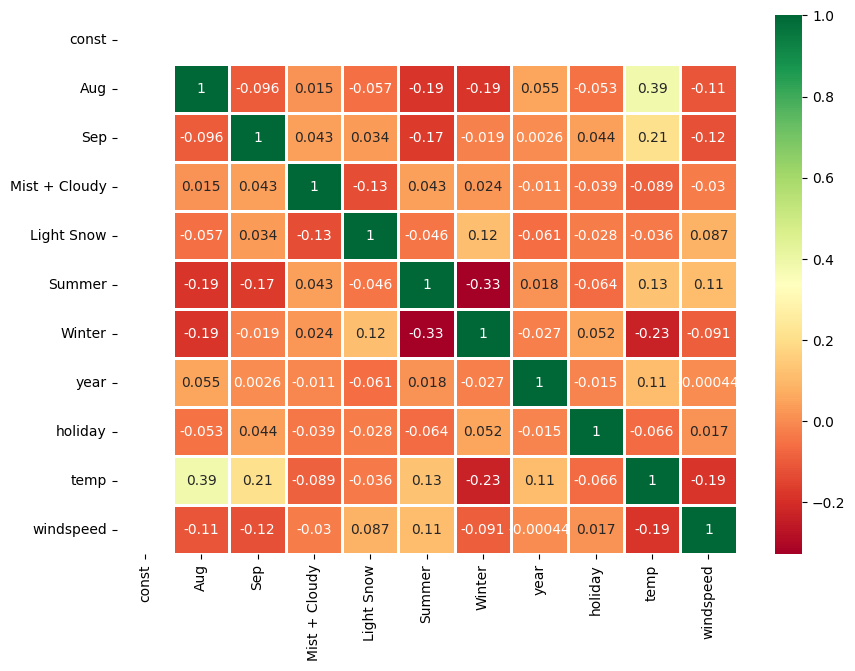

In [121]:
# Validating Multi Colinearity
plt.figure(figsize=(10,7))
sns.heatmap(X_train_lm10.corr(),annot = True, cmap="RdYlGn",linewidth =1)
plt.show()

Heatmap shows no multi-collinearity.

## Making Predictions

#### Applying the scaling on the test sets

In [122]:
#Create a list of numeric variables
num_vars=['temp','humidity','windspeed','count']

#Fit on data
Bike_test[num_vars] = scaler.transform(Bike_test[num_vars])
Bike_test.head()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed,count
184,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0.831783,33.27085,0.657364,0.084219,0.692706
535,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,1,0.901354,36.04875,0.610133,0.153728,0.712034
299,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0.511964,22.85230,0.837699,0.334206,0.303382
221,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0.881625,34.24915,0.437098,0.339570,0.547400
152,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0.817246,32.19710,0.314298,0.537414,0.569029


#### Dividing into X_test and y_test


In [123]:
#Dividing into X_test and y_test
y_test = Bike_test.pop('count')
X_test = Bike_test
X_test.describe()

,Feb,Mar,Apr,May,June,July,Aug,Sep,Oct,Nov,Dec,Mon,Tue,Wed,Thu,Fri,Sat,Mist + Cloudy,Light Snow,Summer,Fall,Winter,year,holiday,workingday,temp,atemp,humidity,windspeed
count,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000
mean,0.100000,0.054545,0.090909,0.086364,0.095455,0.104545,0.059091,0.086364,0.086364,0.072727,0.086364,0.118182,0.122727,0.159091,0.140909,0.131818,0.172727,0.318182,0.027273,0.263636,0.245455,0.236364,0.481818,0.036364,0.640909,0.558718,24.250312,0.638221,0.313293
std,0.300684,0.227609,0.288135,0.281541,0.294512,0.306665,0.236333,0.281541,0.281541,0.260281,0.281541,0.323559,0.328872,0.366595,0.348721,0.339064,0.378873,0.466833,0.163248,0.441609,0.431338,0.425817,0.500809,0.187620,0.480828,0.233187,8.281075,0.148694,0.159584
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.046591,4.941955,0.261915,-0.042808
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.355429,17.090025,0.529197,0.198843
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.558172,24.700000,0.625590,0.300126
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.755981,31.124313,0.743798,0.402718
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.984424,41.318550,1.002146,0.807474


In [124]:
# Columns
X_train_new10.columns

Index(['Aug', 'Sep', 'Mist + Cloudy', 'Light Snow', 'Summer', 'Winter', 'year',
       'holiday', 'temp', 'windspeed'],
      dtype='object')

In [125]:
# Now let's use our model to make predictions.

# Creating X_test_new dataframe by dropping variables from X_test
X_test_new = X_test[X_train_new10.columns]

# Adding a constant variable
X_test_new1 = sm.add_constant(X_test_new)
X_test_new1.head()

,const,Aug,Sep,Mist + Cloudy,Light Snow,Summer,Winter,year,holiday,temp,windspeed
184,1.0,0,0,1,0,0,0,0,1,0.831783,0.084219
535,1.0,0,0,0,0,1,0,1,0,0.901354,0.153728
299,1.0,0,0,1,0,0,1,0,0,0.511964,0.334206
221,1.0,1,0,0,0,0,0,0,0,0.881625,0.339570
152,1.0,0,0,0,0,1,0,0,0,0.817246,0.537414


In [126]:
# Making predictions
y_pred = lm10.predict(X_test_new1)


### Finding R-squared and Adjusted R-Squared for Test set

In [127]:
#Evaluate R-square for test
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.7935224695104377

In [128]:
#Adjusted R^2
#adj r2=1-(1-R2)*(n-1)/(n-p-1)

#n =sample size , p = number of independent variables

Adj_r2=1-(1-0.8115083)*(11-1)/(11-1-1)
print(Adj_r2)

0.7905647777777778


## Model Evaluation

Text(0, 0.5, 'y_pred')

<Figure size 640x480 with 0 Axes>

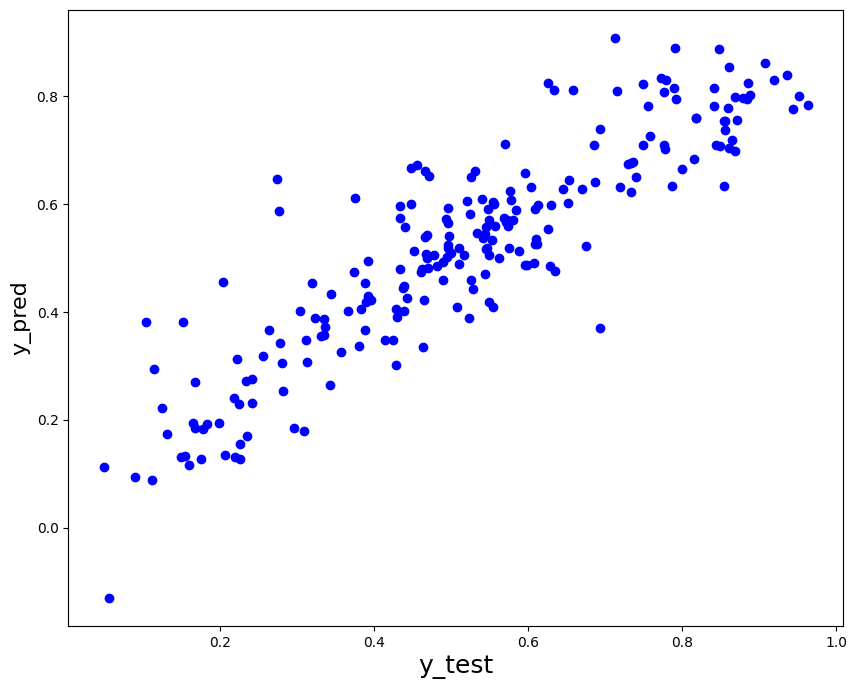

In [129]:
# Plotting y_test and y_pred to understand the spread.
fig = plt.figure()
plt.figure(figsize=(10,8))
plt.scatter(y_test,y_pred,color='blue')

# Plot heading
fig.suptitle('y_test vs y_pred', fontsize=20)

# X-label
plt.xlabel('y_test', fontsize=18)

# Y-label
plt.ylabel('y_pred', fontsize=16)

##### Visualising the fit on the test set

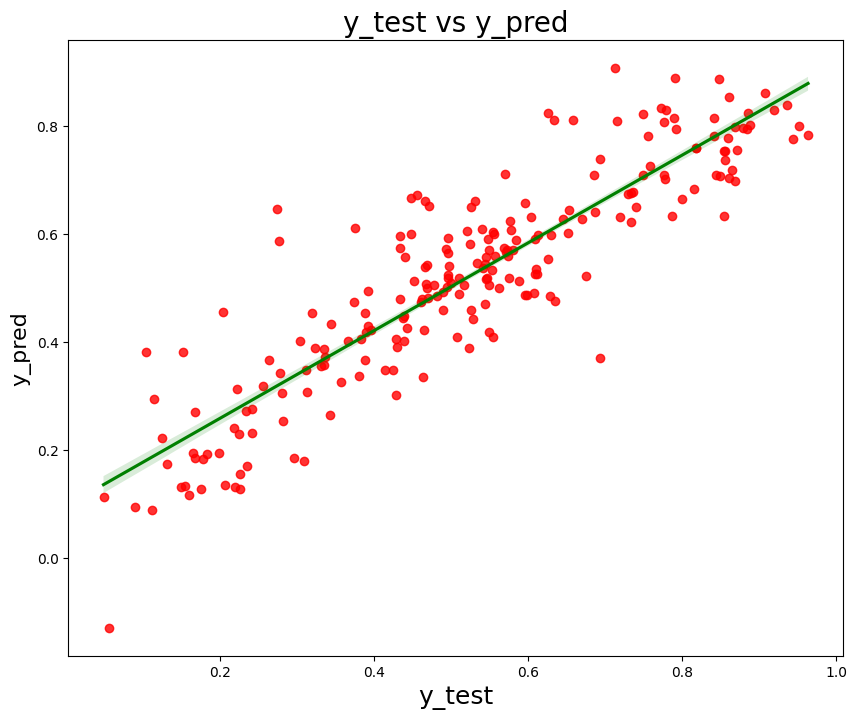

In [130]:
#Regression plot
plt.figure(figsize=(10,8))
sns.regplot(x=y_test, y=y_pred, ci=68, fit_reg=True,scatter_kws={"color": "red"}, line_kws={"color": "green"})

# Plot heading
plt.title('y_test vs y_pred', fontsize=20)

# X-label
plt.xlabel('y_test', fontsize=18)

# Y-label
plt.ylabel('y_pred', fontsize=16)
plt.show()


We can see that the equation of our best fitted line is:

$ count=         0.5173 \times temp+   0.1163   \times September + 0.0541 \times Aug +0.1012 \times summer + 0.1371 \times winter + 0.2326 \times Year + 0.0966 \times holiday   - 0.2819 \times light snow - 0.0811 \times mist cloudy -0.1497 \times windspeed $



---



# Comparison between Train model and Test:

Train R^2 :  0.834

Train Adjusted R^2 : 0.831

Test R^2: 0.793

Test Adjusted R^2: 0.790

Difference in R^2 between train and test: **0.41%**

Difference in adjusted R^2 between Train and test: **0.41%** which is less than 5%.


# Interpretation:

We have successfully developed a robust model for predicting the demand for shared bikes, taking into account the significant variables.

Notably, the temperature variable exhibits the highest coefficient of 0.5173, indicating that a one-unit increase in temperature corresponds to a 0.5173-unit increase in bike rentals.

Furthermore, the equation for the best-fitted line involves coefficients for other variables as well.

Conversely, there are variables with negative coefficients such as windspeed, mist cloudy, and light snow. A negative coefficient implies that an increase in the independent variable results in a decrease in the dependent variable. The coefficient value quantifies how much the mean of the dependent variable changes when the independent variable shifts by one unit while keeping other variables constant in the model.

# Business Goals:

The U.S. bike-sharing provider, BoomBikes, should place a heightened emphasis on temperature factors.

It's evident that the demand for bikes increased in 2019 compared to 2018. Therefore, the company should focus on this upturn, particularly in light of potential revenue challenges brought about by the ongoing COVID-19 pandemic, with an expectation that conditions will improve over time.

Furthermore, BoomBikes can concentrate on the summer and fall seasons, particularly during August and September, along with weekends and working days, as these factors exhibit a positive influence on bike rentals.

Regarding the 'weathersit' variable, it's noteworthy that negative coefficients were found for 'Mist + Cloudy' and 'Light Snow' weather conditions. To stimulate demand, the company may consider offering special promotions or incentives during such weather conditions.




